# Workshop 6

**Task 1 - Distributional shift**

Run the following cell of code to generate the data used in this demo. We have data observed in batches at 11 distinct time points 0, 1, 2, ... 10. We are going to compare models based on whether (and how) they include the new data

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

np.random.seed(42)


def drifting(x, n):
    return 50 - ((10 - n) / 100) * (x - 50 - 2 * n)**2


test_seq = np.arange(0, 101, 2)
error = 30

# Train on original (shift = 0) distribution only
train = pd.DataFrame({
    "x": test_seq,
    "y": drifting(test_seq, 0) + np.random.normal(0, error, len(test_seq))
})


def fit_model(data, weights=None):
    model = make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    )
    model.fit(
        data[["x"]],
        data["y"],
        linearregression__sample_weight=weights
    )
    return model


model = fit_model(train)

# Test: fresh noise at every shift level, multiple replicates
sim = pd.MultiIndex.from_product(
    [range(11), range(1, 6), test_seq],
    names=["shift", "rep", "x"]
).to_frame(index=False)

sim["truth"] = drifting(sim["x"].values, sim["shift"].values)
sim["y"] = sim["truth"] + np.random.normal(0, error, len(sim))

# Initial predictions
sim["pred"] = model.predict(sim[["x"]])

## One-shot model 

This is a static approach. We will train our model by fitting a (quadratic) curve to the data available at time zero. The model performance is measured for each new batch of data. We can see that the model performance degrades (RMSE increases over time) because the true relationship is slowly changing. 

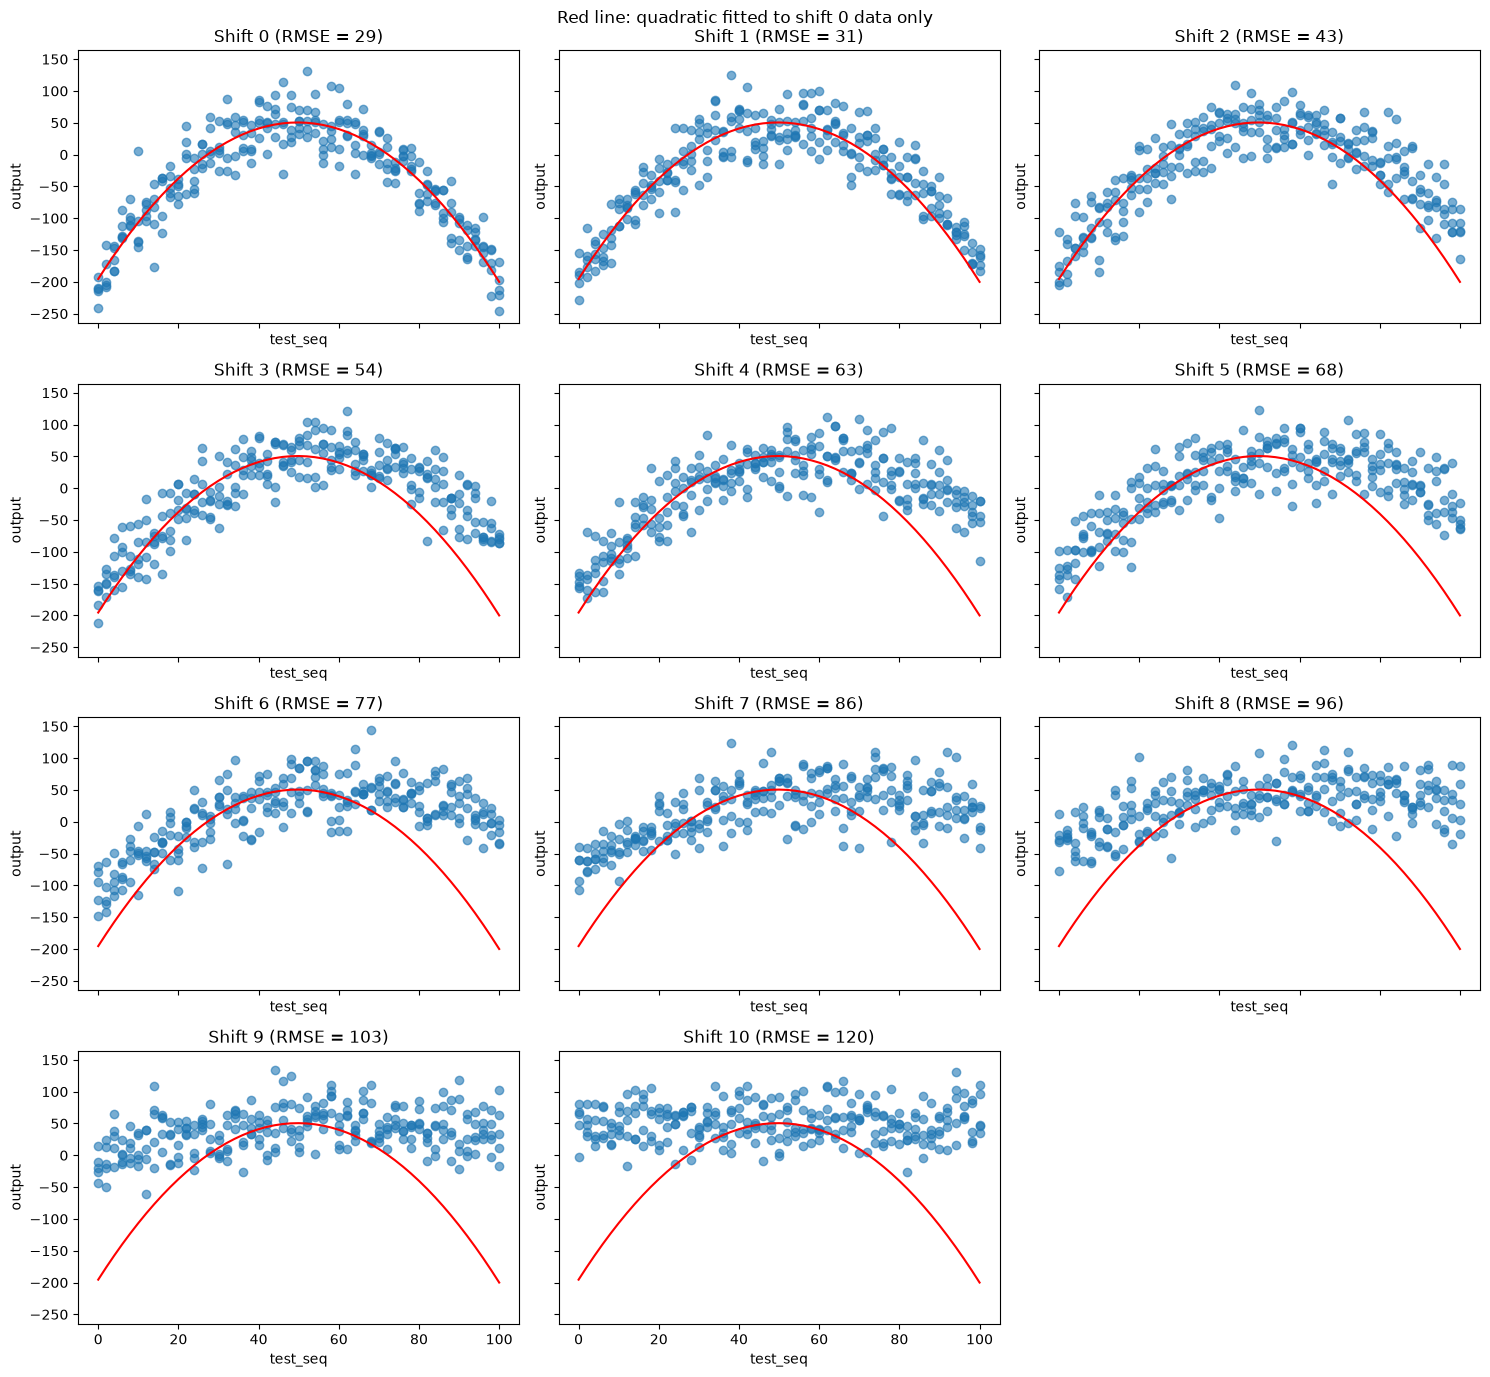

In [6]:
model = fit_model(sim[sim["shift"] == 0])

sim["pred"] = model.predict(sim[["x"]])
sim["resid"] = sim["y"] - sim["pred"]

labels = (
    sim.groupby("shift")["resid"]
    .apply(lambda r: np.sqrt(np.mean(r**2)))
    .reset_index(name="rmse")
)

labels["label"] = labels.apply(
    lambda r: f"Shift {int(r['shift'])} (RMSE = {r['rmse']:.0f})",
    axis=1
)

sim = sim.merge(labels, on="shift")

fig, axes = plt.subplots(4, 3, figsize=(15, 14), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (label, data) in zip(axes, sim.groupby("label", sort=False)):

    ax.scatter(data["x"], data["y"], alpha=0.6)

    curve = data.groupby("x")["pred"].mean()
    ax.plot(curve.index, curve.values, color="red", linewidth=1.5)

    ax.set_title(label)
    ax.set_xlabel("test_seq")
    ax.set_ylabel("output")

for ax in axes[len(sim["label"].unique()):]:
    ax.set_visible(False)

fig.suptitle("Red line: quadratic fitted to shift 0 data only")
plt.tight_layout()
plt.show()

How would you ensure that the model does not deteriorate over time? 

## Comparing some batch re-training strategies

I have assumed that observations in batch 1 have occurred at a random time between 0 and 1 and a prediction of the output needs to be made instantaneously. This means that we can not use batch 1 data to train the model used for this prediction (why is this?). 

The next cell sets up 3 possible approaches: 

1)  At time k retrain using batch k only. The training data stays the same time and is updated to the latest version. 
2) At time k, retrain using batches 0 to k. This makes the training data bigger each time a new batch of data arrives. 
3) A compromise between options 1 and 2. Data from i iterations ago is weighted by decay^i. Small decay behaves like “previous only”, and decay = 1 is “all previous”.

In [16]:
strategies = [
    "Previous only",
    "All previous",
    "Decayed (0.5)"
]


def fit_prev(k, strategy, decay=0.5):

    if strategy == "Previous only":
        data = sim[sim["shift"] == k - 1].copy()

    else:
        data = sim[sim["shift"] < k].copy()

    if strategy == "Decayed (0.5)":
        weights = decay ** (k - 1 - data["shift"].values)
    else:
        weights = np.ones(len(data))

    return fit_model(data, weights=weights)


# Generate prediction curves
curves = []

for k in range(1, 11):
    for strategy in strategies:

        model = fit_prev(k, strategy)

        predictions = model.predict(
            pd.DataFrame({"x": test_seq})
        )

        curves.append(pd.DataFrame({
            "k": k,
            "strategy": strategy,
            "x": test_seq,
            "pred": predictions
        }))

curves = pd.concat(curves, ignore_index=True)

The plots below indicate what happens when we use batch training strategy 1. 

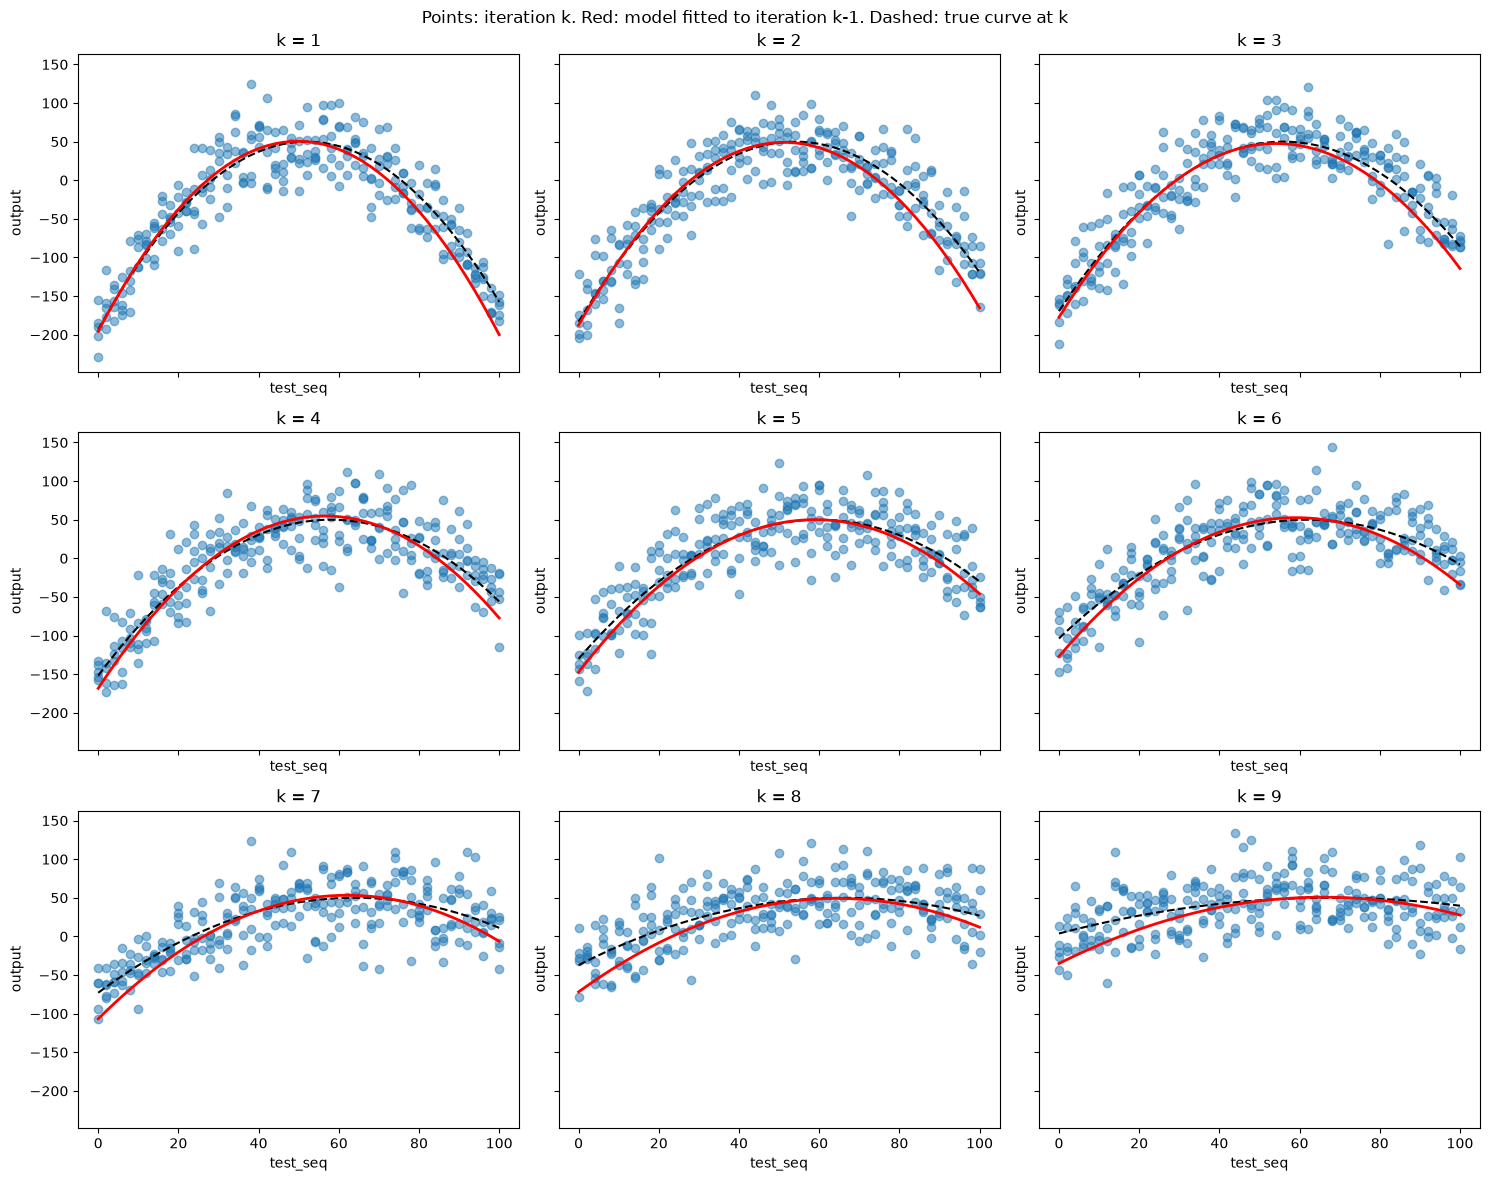

In [17]:
ks = range(1, 10)

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12),
    sharex=True,
    sharey=True
)

for ax, k in zip(axes.flat, ks):

    data = sim[sim["shift"] == k]
    curve = curves[
        (curves["strategy"] == "Previous only") &
        (curves["k"] == k)
    ]

    ax.scatter(data["x"], data["y"], alpha=0.5)

    # True curve
    truth = data.groupby("x")["truth"].mean()
    ax.plot(
        truth.index, truth.values,
        linestyle="--", color="black"
    )

    # Previous iteration prediction
    ax.plot(
        curve["x"], curve["pred"],
        color="red", linewidth=2
    )

    ax.set_title(f"k = {k}")
    ax.set_xlabel("test_seq")
    ax.set_ylabel("output")

fig.suptitle(
    "Points: iteration k. Red: model fitted to iteration k-1. "
    "Dashed: true curve at k"
)

plt.tight_layout()
plt.show()

These look substantially better. 

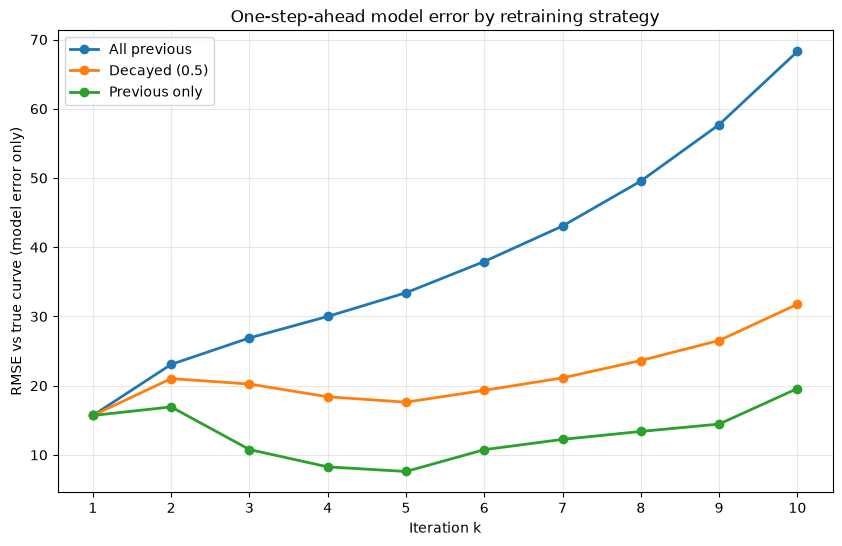

In [18]:
truth_tbl = (
    sim[["shift", "x", "truth"]]
    .drop_duplicates()
    .rename(columns={"shift": "k"})
)

perf = curves.merge(
    truth_tbl,
    on=["k", "x"]
)

perf["sq_error"] = (perf["truth"] - perf["pred"])**2

perf = (
    perf.groupby(["k", "strategy"])["sq_error"]
    .mean()
    .pow(0.5)
    .reset_index(name="rmse_truth")
)

plt.figure(figsize=(10, 6))

for strategy, data in perf.groupby("strategy"):
    plt.plot(
        data["k"],
        data["rmse_truth"],
        marker="o",
        linewidth=2,
        label=strategy
    )

plt.xticks(range(1, 11))
plt.xlabel("Iteration k")
plt.ylabel("RMSE vs true curve (model error only)")
plt.title("One-step-ahead model error by retraining strategy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In terms of predictive error (as summarised by RMSE) strategy 1 appears to be better. However, this metric does not fully reveal the relationship between bias and variance. The next graph shows the fitted lines for each strategy at each point in time so that they can be compared.   

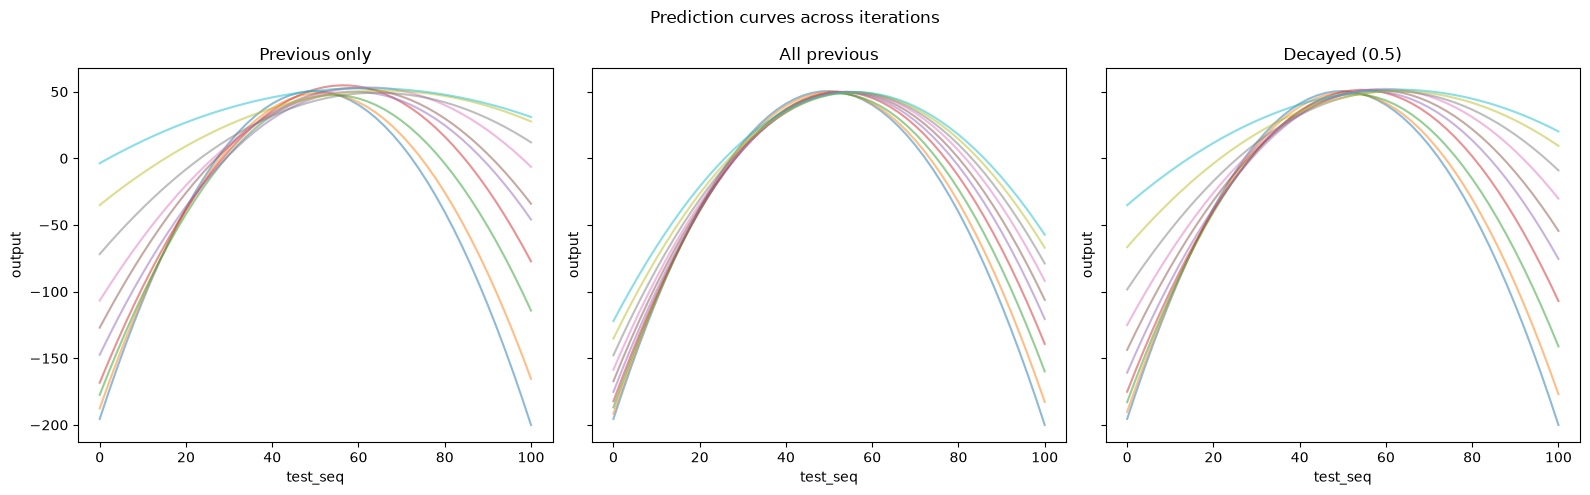

In [19]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharex=True,
    sharey=True
)

for ax, strategy in zip(axes, strategies):

    for k in range(1, 11):

        curve = curves[
            (curves["strategy"] == strategy) &
            (curves["k"] == k)
        ]

        ax.plot(
            curve["x"],
            curve["pred"],
            alpha=0.5
        )

    ax.set_title(strategy)
    ax.set_xlabel("test_seq")
    ax.set_ylabel("output")

plt.suptitle("Prediction curves across iterations")
plt.tight_layout()
plt.show()

There is a trade off between bias and variance. We would expect

1) Previous only: adapts quickly to distributional drift, but estimates the curve from relatively little data. This increases variance.
2) All previous: uses more observations, reducing estimation variance, but old observations become increasingly unrepresentative. This increases bias.
3) Decayed history: balances the two by retaining historical information while giving more weight to recent observations.

The following code simulates more than one batch at each time point using **Monte Carlo simulation** to illustrate the variability 

Monte Carlo simulation complete.


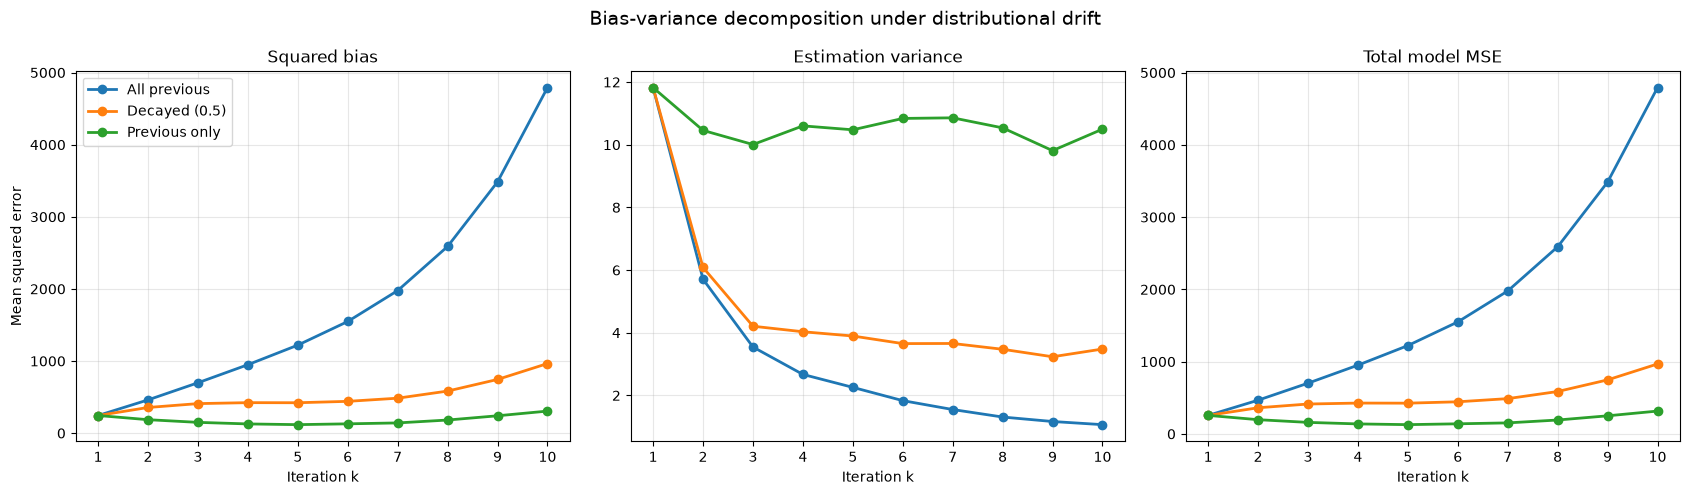

In [20]:
# Number of independent simulation runs
n_runs = 300

strategies = [
    "Previous only",
    "All previous",
    "Decayed (0.5)"
]

n_shifts = 11
n_reps = 5
n_x = len(test_seq)

rng = np.random.default_rng(42)

# Store predictions:
# strategy x iteration x simulation run x x-value

predictions = np.zeros(
    (len(strategies), 10, n_runs, n_x)
)

true_curves = np.array([
    drifting(test_seq, k)
    for k in range(1, 11)
])

for run in range(n_runs):

    # Generate independent observations for this run
    x_values = np.tile(test_seq, n_reps)

    datasets = {}

    for shift in range(n_shifts):

        truth = drifting(x_values, shift)

        y = truth + rng.normal(
            0, error, len(x_values)
        )

        datasets[shift] = pd.DataFrame({
            "x": x_values,
            "y": y,
            "shift": shift
        })

    # Fit models at each iteration
    for k in range(1, 11):

        for s, strategy in enumerate(strategies):

            if strategy == "Previous only":

                train_data = datasets[k - 1].copy()

            else:

                train_data = pd.concat(
                    [datasets[j] for j in range(k)],
                    ignore_index=True
                )

            # Exponential decay weights
            if strategy == "Decayed (0.5)":

                weights = (
                    0.5 ** (k - 1 - train_data["shift"].values)
                )

            else:

                weights = np.ones(len(train_data))

            model = fit_model(
                train_data,
                weights=weights
            )

            predictions[s, k - 1, run, :] = (
                model.predict(
                    pd.DataFrame({"x": test_seq})
                )
            )

print("Monte Carlo simulation complete.")

# Mean prediction across independent simulation runs
mean_predictions = predictions.mean(axis=2)

# Bias squared
bias_squared = np.mean(
    (mean_predictions - true_curves[None, :, :])**2,
    axis=2
)

# Variance across independent runs
variance = np.mean(
    predictions.var(axis=2, ddof=0),
    axis=2
)

# Total expected squared prediction error
mse = np.mean(
    (predictions - true_curves[None, :, None, :])**2,
    axis=(2, 3)
)

# Assemble results
results = []

for s, strategy in enumerate(strategies):

    for k in range(1, 11):

        results.append({
            "strategy": strategy,
            "k": k,
            "bias_squared": bias_squared[s, k-1],
            "variance": variance[s, k-1],
            "mse": mse[s, k-1]
        })

bv = pd.DataFrame(results)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

metrics = [
    ("bias_squared", "Squared bias"),
    ("variance", "Estimation variance"),
    ("mse", "Total model MSE")
]

for ax, (metric, title) in zip(axes, metrics):

    for strategy, data in bv.groupby("strategy"):

        ax.plot(
            data["k"],
            data[metric],
            marker="o",
            linewidth=2,
            label=strategy
        )

    ax.set_title(title)
    ax.set_xlabel("Iteration k")
    ax.set_xticks(range(1, 11))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean squared error")
axes[0].legend()

plt.suptitle(
    "Bias-variance decomposition under distributional drift",
    fontsize=14
)

plt.tight_layout()
plt.show()

There is a cost associated with discarding data. At time k = 10:
- Previous only uses 255 observations (5 replicates × 51 x-values).
- All previous uses 2,550 observations (10 shifts × 5 replicates × 51 x-values).
- Decayed history uses all 2,550 observations, but discounts older observations.

All previous should have lower estimation variance than previous only, but higher bias because much of its training data comes from obsolete distributions.

In [21]:
print(
    bv[bv["k"] == 10]
    .set_index("strategy")[
        ["bias_squared", "variance", "mse"]
    ]
    .round(2)
)

               bias_squared  variance      mse
strategy                                      
Previous only        305.47     10.50   315.97
All previous        4791.39      1.07  4792.45
Decayed (0.5)        964.47      3.48   967.95
